# 03 · Regressão de Séries Temporais e Teste de Durbin-Watson

**PNV-3421 — Processos Estocásticos — Previsão de Demanda**
**Ementa, tópico 3:** *"Regressão de Séries Temporais. Teste de Durbin-Watson"*

### De onde vem este material
Todo o conteúdo vem de `2.5/Aula 08.pdf`, que (assim como a Aula 07) **não tinha nenhum notebook de apoio** na organização original. Este notebook implementa a teoria completa e os 4 exemplos do slide.

### Roteiro
1. O problema: correlação serial dos resíduos em regressões de séries temporais
2. Teste de Durbin-Watson (DW) — fórmula, tabela de valores críticos, regra de decisão
3. Modelos Autorregressivos para corrigir a correlação serial (transformação de Cochrane-Orcutt)
4. Exemplo Introdutório e Exemplo 2 — quando 1 variável não basta
5. Exemplo 2b — adicionar uma variável resolve o problema
6. Exemplo 3 — quando adicionar 1 variável não é suficiente
7. Exemplo 4 — correção completa (estimação de ρ, transformação, nova previsão)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.stattools import durbin_watson

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. O problema: correlação serial dos resíduos

Ao aplicar regressão linear a observações **coletadas ao longo do tempo**, é comum que o valor de Y num período esteja relacionado ao valor de Y no período anterior — e, por consequência, os **resíduos também**. Dizemos que há **correlação serial** (ou autocorrelação) nos resíduos: $e_t$ não é independente de $e_{t-1}$.

### Por que isso importa
1. O erro padrão da estimativa ($s_\varepsilon$) **subestima** a variabilidade real dos erros;
2. Os intervalos de confiança/previsão baseados em $t$ (ou $F$) deixam de ser válidos;
3. O erro padrão dos coeficientes também fica subestimado — testes de hipótese ficam "otimistas demais".

### Correlação serial de 1ª ordem

$$Y_t = \beta_0 + \beta X_t + \epsilon_t, \qquad \epsilon_t = \rho\,\epsilon_{t-1} + v_t$$

onde $\rho$ é o coeficiente de correlação serial de 1ª ordem e $v_t$ é um termo independente, normalmente distribuído.

## 2. O Exemplo Introdutório: vendas x renda líquida (1976-1996)

In [2]:
anos = list(range(1976, 1997))
renda = [273.4,291.3,306.9,317.1,336.1,349.4,362.9,383.9,402.8,437.0,472.2,510.4,544.5,588.1,630.4,685.9,742.8,801.3,903.1,983.6,1076.7]
venda = [295,400,390,425,547,555,620,720,880,1050,1290,1528,1586,1960,2118,2116,2477,3199,3702,3316,2702]
df_intro = pd.DataFrame({'Ano': anos, 'Renda': renda, 'Venda': venda})

modelo_intro = ols('Venda ~ Renda', df_intro).fit()
print(modelo_intro.params)
print(f"R^2 = {modelo_intro.rsquared:.3f}")
dw_intro = durbin_watson(modelo_intro.resid)
print(f"Durbin-Watson = {dw_intro:.3f}")

Intercept   -792.002432
Renda          4.255167
dtype: float64
R^2 = 0.905
Durbin-Watson = 0.871


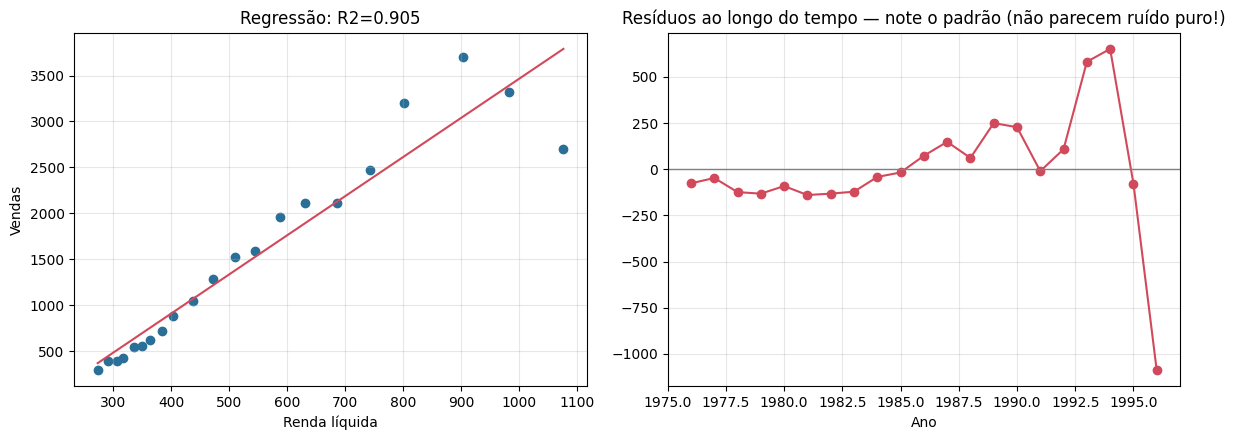

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(df_intro['Renda'], df_intro['Venda'], color='#2a6f97')
xs = np.linspace(df_intro['Renda'].min(), df_intro['Renda'].max(), 10)
axes[0].plot(xs, modelo_intro.params['Intercept'] + modelo_intro.params['Renda']*xs, color='#d1495b')
axes[0].set_title(f"Regressão: R2={modelo_intro.rsquared:.3f}")
axes[0].set_xlabel('Renda líquida'); axes[0].set_ylabel('Vendas')

axes[1].plot(anos, modelo_intro.resid, 'o-', color='#d1495b')
axes[1].axhline(0, color='gray', lw=1)
axes[1].set_title('Resíduos ao longo do tempo — note o padrão (não parecem ruído puro!)')
axes[1].set_xlabel('Ano')
fig.tight_layout()
plt.show()

**Observe o painel direito:** os resíduos não "pulam" aleatoriamente — ficam vários períodos seguidos negativos, depois vários seguidos positivos. Isso é a assinatura visual da correlação serial positiva.

### Treinando o olho: resíduos com padrão vs. resíduos aleatórios

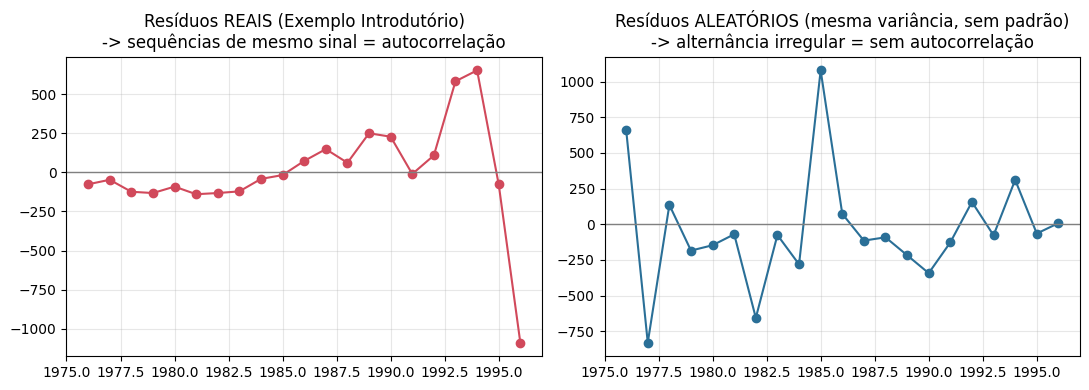

In [4]:
rng = np.random.default_rng(3)
residuos_aleatorios = rng.normal(0, np.std(modelo_intro.resid), len(anos))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(anos, modelo_intro.resid, 'o-', color='#d1495b')
axes[0].axhline(0, color='gray', lw=1)
axes[0].set_title('Resíduos REAIS (Exemplo Introdutório)\n-> sequências de mesmo sinal = autocorrelação')

axes[1].plot(anos, residuos_aleatorios, 'o-', color='#2a6f97')
axes[1].axhline(0, color='gray', lw=1)
axes[1].set_title('Resíduos ALEATÓRIOS (mesma variância, sem padrão)\n-> alternância irregular = sem autocorrelação')
fig.tight_layout()
plt.show()

## 3. Teste de Durbin-Watson

Formaliza a inspeção visual acima com um teste de hipótese:

$$H_0: \rho = 0 \qquad H_1: \rho > 0$$

$$DW = \frac{\sum_{t=2}^n (e_t - e_{t-1})^2}{\sum_{t=1}^n e_t^2}$$

* $DW$ varia de 0 a 4; $DW \approx 2$ indica ausência de correlação; $DW$ próximo de 0 indica correlação positiva forte.
* O teste é **aproximado**: comparamos $DW$ a um limitante inferior $d_L$ e superior $d_U$ (tabelados, em função de $n$ e do nº de variáveis $k$):
  * $DW > d_U$ → aceita-se $H_0$ (resíduos não correlacionados)
  * $DW < d_L$ → aceita-se $H_1$ (resíduos correlacionados)
  * $d_L \le DW \le d_U$ → teste inconclusivo

(Tabela completa de valores críticos: <https://www.real-statistics.com/statistics-tables/durbin-watson-table/>. Abaixo, usamos apenas os pontos citados nos exemplos da Aula 08.)

DW (fórmula manual)   = 0.8713
DW (statsmodels)      = 0.8713


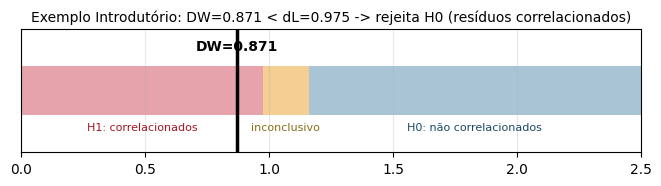

In [5]:
def dw_manual(residuos):
    e = np.asarray(residuos)
    return np.sum(np.diff(e) ** 2) / np.sum(e ** 2)

print(f"DW (fórmula manual)   = {dw_manual(modelo_intro.resid):.4f}")
print(f"DW (statsmodels)      = {durbin_watson(modelo_intro.resid):.4f}")

# Valores críticos tabelados citados no slide para alpha=1%, T=21, K=2 (1 variável independente)
dL_intro, dU_intro = 0.97545, 1.16059

def termometro_dw(dw, dL, dU, titulo, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 1.6))
    lim_sup = max(dU * 1.6, dw * 1.2, 2.5)
    ax.barh(0, dL, color='#d1495b', alpha=0.5)
    ax.barh(0, dU - dL, left=dL, color='#edae49', alpha=0.6)
    ax.barh(0, lim_sup - dU, left=dU, color='#2a6f97', alpha=0.4)
    ax.axvline(dw, color='k', lw=2.5)
    ax.annotate(f'DW={dw:.3f}', (dw, 0.65), ha='center', fontweight='bold')
    ax.text(dL/2, -0.65, 'H1: correlacionados', ha='center', fontsize=8, color='#a31621')
    ax.text((dL+dU)/2, -0.65, 'inconclusivo', ha='center', fontsize=8, color='#8a6d1b')
    ax.text((dU+lim_sup)/2, -0.65, 'H0: não correlacionados', ha='center', fontsize=8, color='#1b4965')
    ax.set_xlim(0, lim_sup); ax.set_ylim(-1, 1); ax.set_yticks([])
    ax.set_title(titulo, fontsize=10)
    return ax

termometro_dw(dw_intro, dL_intro, dU_intro, f'Exemplo Introdutório: DW={dw_intro:.3f} < dL={dL_intro:.3f} -> rejeita H0 (resíduos correlacionados)')
plt.show()

## 4. Exemplo 2 — mesmo problema, recorte 1980-1996

Repetindo a mesma ideia num recorte menor da série (17 observações).

Intercept   -1.504621
Renda        0.029192
dtype: float64
R^2 = 0.995   DW = 0.722


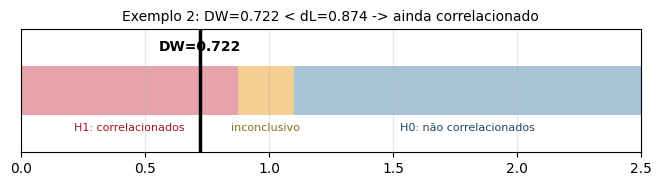

In [6]:
renda2 = [336.1,349.4,362.9,383.9,402.8,437.0,472.2,510.4,544.5,588.1,630.4,685.9,742.8,801.3,903.1,983.6,1076.7]
venda2 = [8.0,8.2,8.5,9.2,10.2,11.4,12.8,13.6,14.6,16.4,17.8,18.6,20.0,21.9,24.9,27.3,29.1]
df_ex2 = pd.DataFrame({'Renda': renda2, 'Venda': venda2})

modelo_ex2 = ols('Venda ~ Renda', df_ex2).fit()
dw_ex2 = durbin_watson(modelo_ex2.resid)
print(modelo_ex2.params)
print(f"R^2 = {modelo_ex2.rsquared:.3f}   DW = {dw_ex2:.3f}")

dL_ex2, dU_ex2 = 0.87363, 1.10210  # T=17, K=2, alpha=1%
termometro_dw(dw_ex2, dL_ex2, dU_ex2, f'Exemplo 2: DW={dw_ex2:.3f} < dL={dL_ex2:.3f} -> ainda correlacionado')
plt.show()

## 5. Exemplo 2b — acrescentando a taxa de desemprego

A causa mais comum de correlação serial é a **ausência de uma variável explicativa relevante**. Vamos acrescentar a taxa de desemprego da região.

Intercept   -0.014022
Renda        0.029749
Taxa        -0.349869
dtype: float64
R^2 = 0.9991   DW = 1.980


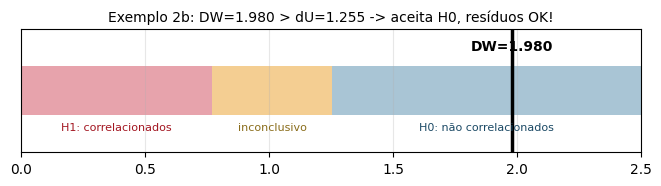

In [7]:
taxa = [5.5,5.5,6.7,5.5,5.7,5.2,4.5,3.8,3.8,3.6,3.5,4.9,5.9,5.6,4.9,5.6,8.5]
df_ex2b = df_ex2.copy()
df_ex2b['Taxa'] = taxa

modelo_ex2b = ols('Venda ~ Renda + Taxa', df_ex2b).fit()
dw_ex2b = durbin_watson(modelo_ex2b.resid)
print(modelo_ex2b.params)
print(f"R^2 = {modelo_ex2b.rsquared:.4f}   DW = {dw_ex2b:.3f}")

dL_ex2b, dU_ex2b = 0.77209, 1.25512  # T=17, K=3, alpha=1%
termometro_dw(dw_ex2b, dL_ex2b, dU_ex2b, f'Exemplo 2b: DW={dw_ex2b:.3f} > dU={dU_ex2b:.3f} -> aceita H0, resíduos OK!')
plt.show()

**Vitória rápida:** ao incluir a taxa de desemprego, $DW$ salta de 0,72 para 1,98 — passa a ficar **acima** de $d_U$, então aceitamos $H_0$: os resíduos deixaram de ser (detectavelmente) correlacionados. Esse é o desfecho ideal: encontrar a variável omitida resolve o problema de uma vez.

Nem sempre, porém, existe uma variável explicativa óbvia disponível. Para esses casos, existe uma correção puramente estatística: os **modelos autorregressivos**.

## 6. Modelos Autorregressivos: corrigindo a correlação serial

Partindo de $Y_t = \beta_0 + \beta X_t + \epsilon_t$ e $\epsilon_t = \rho\,\epsilon_{t-1} + v_t$, subtraímos $\rho$ vezes a equação defasada em 1 período:

$$Y_t - \rho Y_{t-1} = (\beta_0 - \rho\beta_0) + (\beta X_t - \rho\beta X_{t-1}) + (\epsilon_t - \rho\epsilon_{t-1})$$

Definindo $Y_t' = Y_t - \rho Y_{t-1}$, $X_t' = X_t - \rho X_{t-1}$ e $\beta_0' = \beta_0(1-\rho)$:

$$Y_t' = \beta_0' + \beta X_t' + v_t$$

Nesta nova regressão, os erros $v_t$ **não** têm correlação serial — e a inclinação $\beta$ é preservada (só o intercepto muda de forma).

### Estimando ρ
1. Correlação entre os resíduos e os resíduos defasados em 1 período.
2. Método de **Cochrane-Orcutt**:
$$\hat\rho = \frac{\sum_{t=2}^n e_t e_{t-1}}{\sum_{t=2}^n e_{t-1}^2}$$

In [8]:
def estima_rho(residuos):
    e = np.asarray(residuos)
    rho_correlacao = np.corrcoef(e[1:], e[:-1])[0, 1]
    rho_cochrane_orcutt = np.sum(e[1:] * e[:-1]) / np.sum(e[:-1] ** 2)
    return rho_correlacao, rho_cochrane_orcutt

def transforma_cochrane_orcutt(df, y_col, x_cols, rho):
    dft = df.copy().reset_index(drop=True)
    novo = {}
    for col in [y_col] + list(x_cols):
        novo[col + "_t"] = dft[col] - rho * dft[col].shift(1)
    out = pd.DataFrame(novo).dropna().reset_index(drop=True)
    return out

## 7. Exemplo 3 — quando 1 rodada de correção não basta

Agora usamos a série de **vendas (10³ \$)** do mesmo produto, 1976-1996, de novo explicada só pela renda.

Intercept   -502.408604
Renda         14.025034
dtype: float64
R^2 = 0.991   DW = 0.640

rho (correlação defasada)  = 0.6272
rho (Cochrane-Orcutt)      = 0.8118


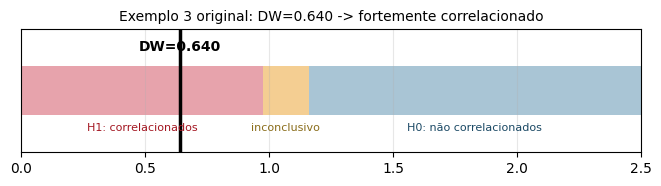

In [9]:
venda3 = [3307,3556,3601,3721,4036,4134,4268,4758,5093,5716,6357,6769,7296,8178,8844,9251,10006,11200,12500,13101,13640]
df_ex3 = pd.DataFrame({'Ano': anos, 'Renda': renda, 'Venda': venda3})

modelo_ex3 = ols('Venda ~ Renda', df_ex3).fit()
dw_ex3 = durbin_watson(modelo_ex3.resid)
print(modelo_ex3.params)
print(f"R^2 = {modelo_ex3.rsquared:.3f}   DW = {dw_ex3:.3f}")

rho_corr, rho_co = estima_rho(modelo_ex3.resid)
print(f"\nrho (correlação defasada)  = {rho_corr:.4f}")
print(f"rho (Cochrane-Orcutt)      = {rho_co:.4f}")

dL_ex3, dU_ex3 = 0.97545, 1.16059  # T=21, K=2, alpha=1%
termometro_dw(dw_ex3, dL_ex3, dU_ex3, f'Exemplo 3 original: DW={dw_ex3:.3f} -> fortemente correlacionado')
plt.show()

Intercept   -29.177194
Renda_t      13.221334
dtype: float64
DW (após 1 transformação, rho=0.627) = 0.881


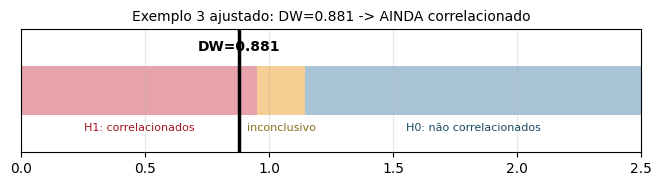

In [10]:
rho_usado = round(rho_corr, 3)
transformado3 = transforma_cochrane_orcutt(df_ex3, 'Venda', ['Renda'], rho_usado)
modelo_ex3_ajustado = ols('Venda_t ~ Renda_t', transformado3).fit()
dw_ex3_ajustado = durbin_watson(modelo_ex3_ajustado.resid)
print(modelo_ex3_ajustado.params)
print(f"DW (após 1 transformação, rho={rho_usado}) = {dw_ex3_ajustado:.3f}")

dL_ex3b, dU_ex3b = 0.952, 1.147  # T=20, K=2, alpha=1%
termometro_dw(dw_ex3_ajustado, dL_ex3b, dU_ex3b, f'Exemplo 3 ajustado: DW={dw_ex3_ajustado:.3f} -> AINDA correlacionado')
plt.show()

**Lição do Exemplo 3:** uma única transformação de Cochrane-Orcutt **não resolveu** o problema — o DW continua abaixo de $d_L$. O slide conclui que, neste caso, a solução correta é **adicionar outra variável explicativa** (como fizemos no Exemplo 2b), e não insistir em mais rodadas de correção autorregressiva. Moral: a correção autorregressiva é um recurso estatístico de último caso, não um substituto para encontrar a variável omitida.

## 8. Exemplo 4 — correção bem-sucedida, passo a passo

Dataset com 39 observações (X, Y) onde a regressão simples apresenta DW baixo. Vamos aplicar a correção completa.

Intercept   -11.526616
X             0.136426
dtype: float64
R^2 = 0.836   DW = 1.116


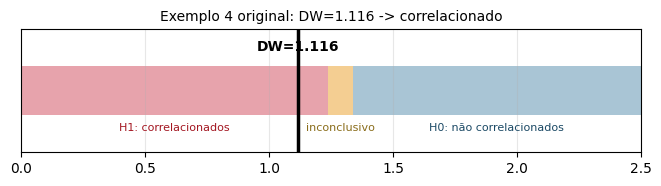

In [11]:
X = [85.54,85.54,85.63,85.08,84.50,84.57,89.08,89.27,89.34,89.82,90.38,90.86,80.25,80.02,80.13,80.69,80.67,80.69,80.74,80.71,
     80.64,86.97,87.77,87.91,88.05,88.44,88.97,83.28,83.07,82.84,82.65,82.77,82.77,82.65,82.35,82.65,82.38,82.45,82.75]
Y = [0.6714894,0.6784707,0.7781225,-0.273323,0.1297735,0.0858459,0.5436565,0.5651866,0.6508005,0.7829627,0.7983509,0.8479512,
     -0.894701,-0.718794,-0.699353,-0.69569,-0.465024,-0.393902,-0.634646,-0.367182,
     -0.316156,0.2889577,0.3409281,0.3281562,0.2104538,0.430642,0.5209901,-0.295232,-0.242121,-0.160644,
     -0.253704,-0.357107,-0.292386,-0.421149,-0.334685,-0.24966,-0.28272,-0.166732,-0.170216]
df_ex4 = pd.DataFrame({'X': X, 'Y': Y})

modelo_ex4 = ols('Y ~ X', df_ex4).fit()
dw_ex4 = durbin_watson(modelo_ex4.resid)
print(modelo_ex4.params)
print(f"R^2 = {modelo_ex4.rsquared:.3f}   DW = {dw_ex4:.3f}")

dL_ex4, dU_ex4 = 1.23655, 1.33711  # T=39, K=2, alpha=1%
termometro_dw(dw_ex4, dL_ex4, dU_ex4, f'Exemplo 4 original: DW={dw_ex4:.3f} -> correlacionado')
plt.show()

rho (correlação defasada) = 0.3896   rho (Cochrane-Orcutt) = 0.3538  (próximos -> estimativas consistentes)

 Intercept   -7.056608
X_t          0.136572
dtype: float64
R^2 = 0.804   DW = 2.358


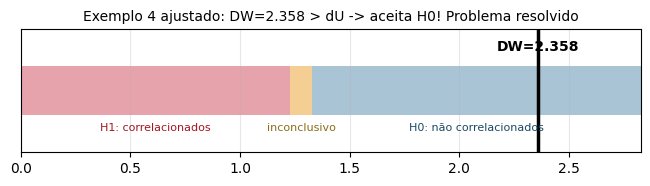

In [12]:
rho_corr4, rho_co4 = estima_rho(modelo_ex4.resid)
print(f"rho (correlação defasada) = {rho_corr4:.4f}   rho (Cochrane-Orcutt) = {rho_co4:.4f}  (próximos -> estimativas consistentes)")

rho4 = round(rho_corr4, 4)
transformado4 = transforma_cochrane_orcutt(df_ex4, 'Y', ['X'], rho4)
modelo_ex4_ajustado = ols('Y_t ~ X_t', transformado4).fit()
dw_ex4_ajustado = durbin_watson(modelo_ex4_ajustado.resid)
print("\n", modelo_ex4_ajustado.params)
print(f"R^2 = {modelo_ex4_ajustado.rsquared:.3f}   DW = {dw_ex4_ajustado:.3f}")

dL_ex4b, dU_ex4b = 1.22681, 1.32997  # T=38, K=2, alpha=1%
termometro_dw(dw_ex4_ajustado, dL_ex4b, dU_ex4b, f'Exemplo 4 ajustado: DW={dw_ex4_ajustado:.3f} > dU -> aceita H0! Problema resolvido')
plt.show()

### Usando o modelo ajustado para previsão

Para prever $Y_{t}$ é preciso "desfazer" a transformação: $\hat Y_t = \rho Y_{t-1} + \beta_0' + \beta(X_t - \rho X_{t-1})$ — por isso o nome **autorregressivo**: a previsão depende do valor **observado** de $Y$ no período anterior.

In [13]:
b0_t, b_t = modelo_ex4_ajustado.params['Intercept'], modelo_ex4_ajustado.params['X_t']
x_ant, y_ant = df_ex4['X'].iloc[-1], df_ex4['Y'].iloc[-1]
x_novo = 83.00

x_novo_t = x_novo - rho4 * x_ant
y_novo_t_hat = b0_t + b_t * x_novo_t
y_novo_hat = y_novo_t_hat + rho4 * y_ant

sse_t = np.sum(modelo_ex4_ajustado.resid ** 2)
gl_t = len(transformado4) - 2
s_eps_t = np.sqrt(sse_t / gl_t)
s_f_t = s_eps_t * np.sqrt(1 + 1/len(transformado4) + (x_novo_t - transformado4['X_t'].mean())**2 / np.sum((transformado4['X_t']-transformado4['X_t'].mean())**2))
t95_t = st.t.ppf(0.975, gl_t)

print(f"Previsão ajustada para X_40={x_novo}: Y_hat = {y_novo_hat:.4f}")
print(f"IP 95%: [{y_novo_hat - t95_t*s_f_t:.3f} ; {y_novo_hat + t95_t*s_f_t:.3f}]")

# Comparando com a regressão original (ingênua, sem corrigir DW -> IP não confiável)
pred_original = modelo_ex4.get_prediction(pd.DataFrame({'X': [x_novo]})).summary_frame(alpha=0.05)
print(f"\nPrevisão da regressão ORIGINAL (não confiável, resíduos correlacionados): Y_hat = {pred_original['mean'][0]:.4f}")
print(f"IP 95% (não confiável): [{pred_original['obs_ci_lower'][0]:.3f} ; {pred_original['obs_ci_upper'][0]:.3f}]")

Previsão ajustada para X_40=83.0: Y_hat = -0.1904
IP 95%: [-0.551 ; 0.170]

Previsão da regressão ORIGINAL (não confiável, resíduos correlacionados): Y_hat = -0.2033
IP 95% (não confiável): [-0.630 ; 0.223]


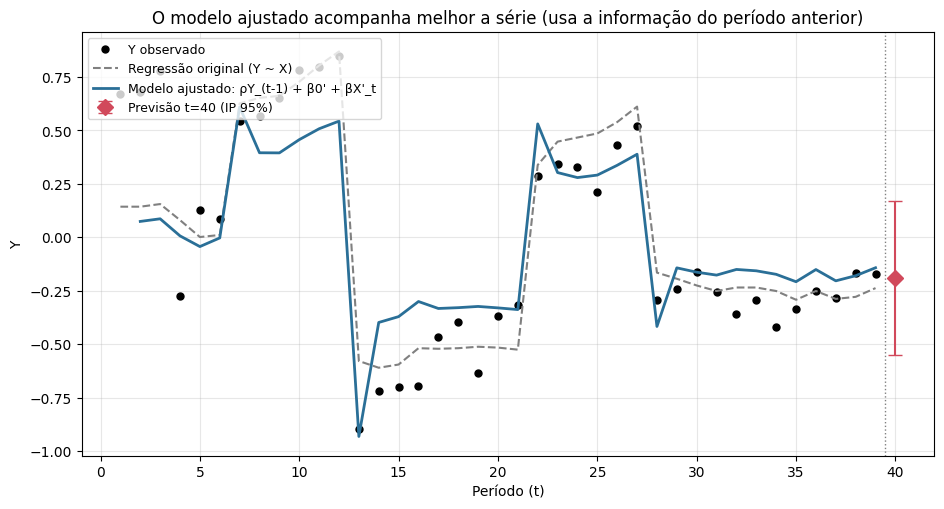

In [14]:
fig, ax = plt.subplots(figsize=(11, 5.5))
t_idx = np.arange(1, len(df_ex4) + 1)
ax.plot(t_idx, df_ex4['Y'], 'o', color='k', ms=5, label='Y observado')
ax.plot(t_idx, modelo_ex4.fittedvalues, '--', color='gray', lw=1.5, label='Regressão original (Y ~ X)')
ax.plot(t_idx[1:], modelo_ex4_ajustado.fittedvalues, color='#2a6f97', lw=2,
        label="Modelo ajustado: ρY_(t-1) + β0' + βX'_t")
ax.errorbar([len(df_ex4) + 1], [y_novo_hat],
            yerr=[[y_novo_hat - (y_novo_hat - t95_t*s_f_t)], [(y_novo_hat + t95_t*s_f_t) - y_novo_hat]],
            fmt='D', color='#d1495b', capsize=5, ms=8, label='Previsão t=40 (IP 95%)')
ax.axvline(len(df_ex4) + 0.5, color='gray', ls=':', lw=1)
ax.set_xlabel('Período (t)'); ax.set_ylabel('Y')
ax.set_title('O modelo ajustado acompanha melhor a série (usa a informação do período anterior)')
ax.legend(fontsize=9, loc='upper left')
plt.show()

**Conclusão do Exemplo 4:** depois de identificar e corrigir a correlação serial, temos (a) um teste de hipótese válido sobre o coeficiente angular, (b) um erro padrão de previsão correto, e (c) um modelo que, na prática, "persegue" a série de perto porque incorpora o valor observado do período anterior — e não apenas a variável explicativa $X$.

---
*Próximo notebook da sequência: [`04_ARIMA_Box_Jenkins.ipynb`](04_ARIMA_Box_Jenkins.ipynb) — quando a própria série (sem variável explicativa externa) já carrega toda a informação necessária para a previsão.*